# IMPORT DATA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

sns.set_style("whitegrid")
sns.set_context("talk")
sns.set_palette(sns.color_palette("ch:s=.25,rot=-.25", 5))

In [2]:
'''Import data : 
- Sumber = marketing_growth_analytics.csv
- Nama = Marketing growth analytics
- Format = CSV
- Tujuan = Untuk menganalisa data tersebut
'''

data = pd.read_csv("marketing_growth_analytics.csv")

# DATA EXPLORATION

### Data diubah menjadi dataframe

In [3]:
marketing = pd.DataFrame(data)
marketing

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,2025-02-14,Email,facebook,Mobile,6,2,0,0,0,0,0,49,1470,0,0
796,797,2025-01-21,Email,instagram,Mobile,5,10,0,1,1,361793,0,47,564,0,2
797,798,2025-01-11,Email,tiktok,Tablet,3,14,0,1,0,0,0,5,195,0,0
798,799,2025-02-19,Social Media,tiktok,Mobile,5,16,0,0,0,0,0,3,84,0,0


Dataset memiliki dimensi :

Jumlah Baris = 800

Jumlah Kolom = 16

In [4]:
marketing.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   user_id           800 non-null    int64
 1   first_visit_date  800 non-null    str  
 2   channel           800 non-null    str  
 3   source            800 non-null    str  
 4   device            800 non-null    str  
 5   sessions          800 non-null    int64
 6   page_views        800 non-null    int64
 7   bounce            800 non-null    int64
 8   add_to_cart       800 non-null    int64
 9   purchase          800 non-null    int64
 10  revenue           800 non-null    int64
 11  ad_cost           800 non-null    int64
 12  clicks            800 non-null    int64
 13  impressions       800 non-null    int64
 14  repeat_purchase   800 non-null    int64
 15  retention_month   800 non-null    int64
dtypes: int64(12), str(4)
memory usage: 125.8 KB


pada kolom first_visit_date nantinya akan diubah tipe data nya menjadi datetime, supaya menjadi format datetime bukan string

In [5]:
marketing.describe().round(2)

,user_id,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
count,800.00,800.00,800.00,800.00,800.00,800.00,800.00,800.00,800.00,800.00,800.00,800.00
mean,400.50,4.13,10.05,0.03,0.41,0.19,51254.88,13686.13,24.37,553.38,0.06,0.43
std,231.08,1.97,5.48,0.18,0.49,0.39,121909.73,23499.47,14.37,427.27,0.24,1.10
min,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,8.00,0.00,0.00
25%,200.75,3.00,5.00,0.00,0.00,0.00,0.00,0.00,11.00,208.75,0.00,0.00
50%,400.50,4.00,10.00,0.00,0.00,0.00,0.00,0.00,23.00,442.00,0.00,0.00
75%,600.25,6.00,15.00,0.00,1.00,0.00,0.00,21996.75,37.00,812.00,0.00,0.00
max,800.00,7.00,19.00,1.00,1.00,1.00,495675.00,79437.00,49.00,1911.00,1.00,5.00


In [6]:
marketing.describe(include="string")

,first_visit_date,channel,source,device
count,800,800,800,800
unique,60,5,6,3
top,2025-02-16,Paid Ads,instagram,Mobile
freq,20,251,143,504


In [7]:
marketing.duplicated().sum()

np.int64(0)

In [8]:
duplicate_persentase = marketing.duplicated().mean() * 100

print(f"Persentase duplicate: {duplicate_persentase:.2f}%")

Persentase duplicate: 0.00%


In [9]:
marketing_clean = pd.DataFrame({
    "data_missing": marketing.isna().sum(),
    "persentase": (marketing.isna().mean()*100).round(2)
})

marketing_clean = marketing_clean[marketing_clean["data_missing"]>0]
marketing_clean

,data_missing,persentase


Tidak terdapat missing value pada data tersebut

### Cek outlier

#### Sessions

In [10]:
Q1 = marketing["sessions"].quantile(0.25)
Q3 = marketing["sessions"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["sessions"] < lower) |
    (marketing["sessions"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["sessions"].count())

Q1: 3.0
Q3: 6.0
IQR: 3.0
Lower Bound: -1.5
Upper Bound: 10.5
Jumlah Outlier: 0


#### Page Views

In [11]:
Q1 = marketing["page_views"].quantile(0.25)
Q3 = marketing["page_views"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["page_views"] < lower) |
    (marketing["page_views"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["page_views"].count())

Q1: 5.0
Q3: 15.0
IQR: 10.0
Lower Bound: -10.0
Upper Bound: 30.0
Jumlah Outlier: 0


#### Bounce

In [12]:
Q1 = marketing["bounce"].quantile(0.25)
Q3 = marketing["bounce"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["bounce"] < lower) |
    (marketing["bounce"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["bounce"].count())

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Jumlah Outlier: 26


#### Add_to_cart

In [13]:
Q1 = marketing["add_to_cart"].quantile(0.25)
Q3 = marketing["add_to_cart"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["add_to_cart"] < lower) |
    (marketing["add_to_cart"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["add_to_cart"].count())

Q1: 0.0
Q3: 1.0
IQR: 1.0
Lower Bound: -1.5
Upper Bound: 2.5
Jumlah Outlier: 0


#### Purchase

In [14]:
Q1 = marketing["purchase"].quantile(0.25)
Q3 = marketing["purchase"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["purchase"] < lower) |
    (marketing["purchase"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["purchase"].count())

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Jumlah Outlier: 150


#### Revenue

In [15]:
Q1 = marketing["revenue"].quantile(0.25)
Q3 = marketing["revenue"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["revenue"] < lower) |
    (marketing["revenue"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["revenue"].count())

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Jumlah Outlier: 150


#### Ad_cost

In [16]:
Q1 = marketing["ad_cost"].quantile(0.25)
Q3 = marketing["ad_cost"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["ad_cost"] < lower) |
    (marketing["ad_cost"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["ad_cost"].count())

Q1: 0.0
Q3: 21996.75
IQR: 21996.75
Lower Bound: -32995.125
Upper Bound: 54991.875
Jumlah Outlier: 89


#### Clicks

In [17]:
Q1 = marketing["clicks"].quantile(0.25)
Q3 = marketing["clicks"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["clicks"] < lower) |
    (marketing["clicks"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["clicks"].count())

Q1: 11.0
Q3: 37.0
IQR: 26.0
Lower Bound: -28.0
Upper Bound: 76.0
Jumlah Outlier: 0


#### Impressions

In [18]:
Q1 = marketing["impressions"].quantile(0.25)
Q3 = marketing["impressions"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["impressions"] < lower) |
    (marketing["impressions"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["impressions"].count())

Q1: 208.75
Q3: 812.0
IQR: 603.25
Lower Bound: -696.125
Upper Bound: 1716.875
Jumlah Outlier: 7


#### Repeat_Purchase

In [19]:
Q1 = marketing["repeat_purchase"].quantile(0.25)
Q3 = marketing["repeat_purchase"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["repeat_purchase"] < lower) |
    (marketing["repeat_purchase"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["repeat_purchase"].count())

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Jumlah Outlier: 48


#### Retention_month

In [20]:
Q1 = marketing["retention_month"].quantile(0.25)
Q3 = marketing["retention_month"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = marketing[
    (marketing["retention_month"] < lower) |
    (marketing["retention_month"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["retention_month"].count())

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Jumlah Outlier: 150


### Cek distribusi data

#### Distribusi numerikal

In [21]:
marketing_distribusi = [["device","sessions","page_views","bounce","add_to_cart","purchase","revenue","ad_cost","clicks",
                         "impressions","repeat_purchase","retention_month"]]

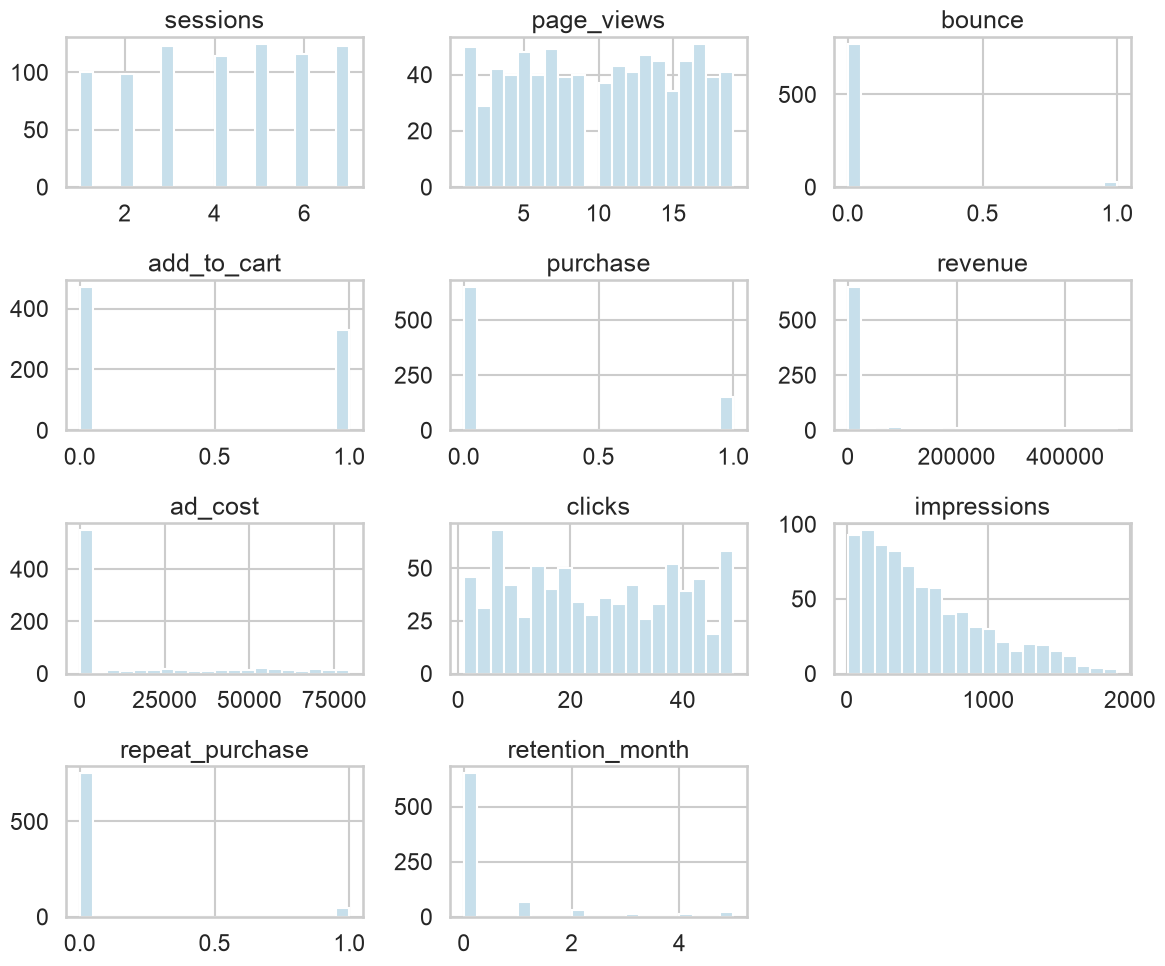

In [22]:
marketing[marketing_distribusi[0]].hist(
    bins=20,
    figsize=(12, 10)
)

plt.tight_layout()
plt.show()

Insight dari data exploration yang bisa disimpulkan yaitu, dataset memiliki variabel numerik dan kategorikal, tidak ditemukannya missing value pada dataset tersebut, pada kolom first_visit_date juga perlu dibuah tipe datanya supaya menjadi format datetime agar lebih sesuai dan bukan string. 

# DATA PREPARATION

## DATA CLEANING

In [23]:
marketing_copy = marketing.copy()

#### Inkonsistensi data

In [24]:
marketing_copy["channel"].unique()

<ArrowStringArray>
['Referral', 'Paid Ads', 'Organic Search', 'Social Media', 'Email']
Length: 5, dtype: str

In [25]:
marketing_copy["source"].unique()

<ArrowStringArray>
['instagram', 'facebook', 'tiktok', 'direct', 'google', 'email']
Length: 6, dtype: str

In [26]:
marketing_copy["device"].unique()

<ArrowStringArray>
['Mobile', 'Desktop', 'Tablet']
Length: 3, dtype: str

### Handling tipe data pada kolom first_visit_date

In [41]:
marketing_copy['first_visit_date'] = pd.to_datetime(marketing_copy['first_visit_date'])

In [28]:
marketing_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           800 non-null    int64         
 1   first_visit_date  800 non-null    datetime64[us]
 2   channel           800 non-null    str           
 3   source            800 non-null    str           
 4   device            800 non-null    str           
 5   sessions          800 non-null    int64         
 6   page_views        800 non-null    int64         
 7   bounce            800 non-null    int64         
 8   add_to_cart       800 non-null    int64         
 9   purchase          800 non-null    int64         
 10  revenue           800 non-null    int64         
 11  ad_cost           800 non-null    int64         
 12  clicks            800 non-null    int64         
 13  impressions       800 non-null    int64         
 14  repeat_purchase   800 non-null    int

### Encoder

In [29]:
le = LabelEncoder()

In [30]:
marketing_copy["channel_Code"] = le.fit_transform(marketing_copy["channel"])
marketing_copy["source_Code"] = le.fit_transform(marketing_copy["source"])
marketing_copy["device_Code"] = le.fit_transform(marketing_copy["device"])

In [31]:
marketing_statistik = marketing_copy[["channel_Code","source_Code","device_Code","device","sessions","page_views","bounce","add_to_cart","purchase","revenue","ad_cost","clicks",
                         "impressions","repeat_purchase","retention_month"]]
marketing_statistik

,channel_Code,source_Code,device_Code,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,3,4,1,Mobile,7,4,0,1,1,401318,0,40,880,0,2
1,3,2,1,Mobile,3,5,0,0,0,0,0,12,264,0,0
2,3,5,1,Mobile,4,5,0,0,0,0,0,3,72,0,0
3,2,2,1,Mobile,4,2,0,1,0,0,18215,16,320,0,0
4,3,4,1,Mobile,1,18,0,0,0,0,0,44,792,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,0,2,1,Mobile,6,2,0,0,0,0,0,49,1470,0,0
796,0,4,1,Mobile,5,10,0,1,1,361793,0,47,564,0,2
797,0,5,2,Tablet,3,14,0,1,0,0,0,5,195,0,0
798,4,5,1,Mobile,5,16,0,0,0,0,0,3,84,0,0


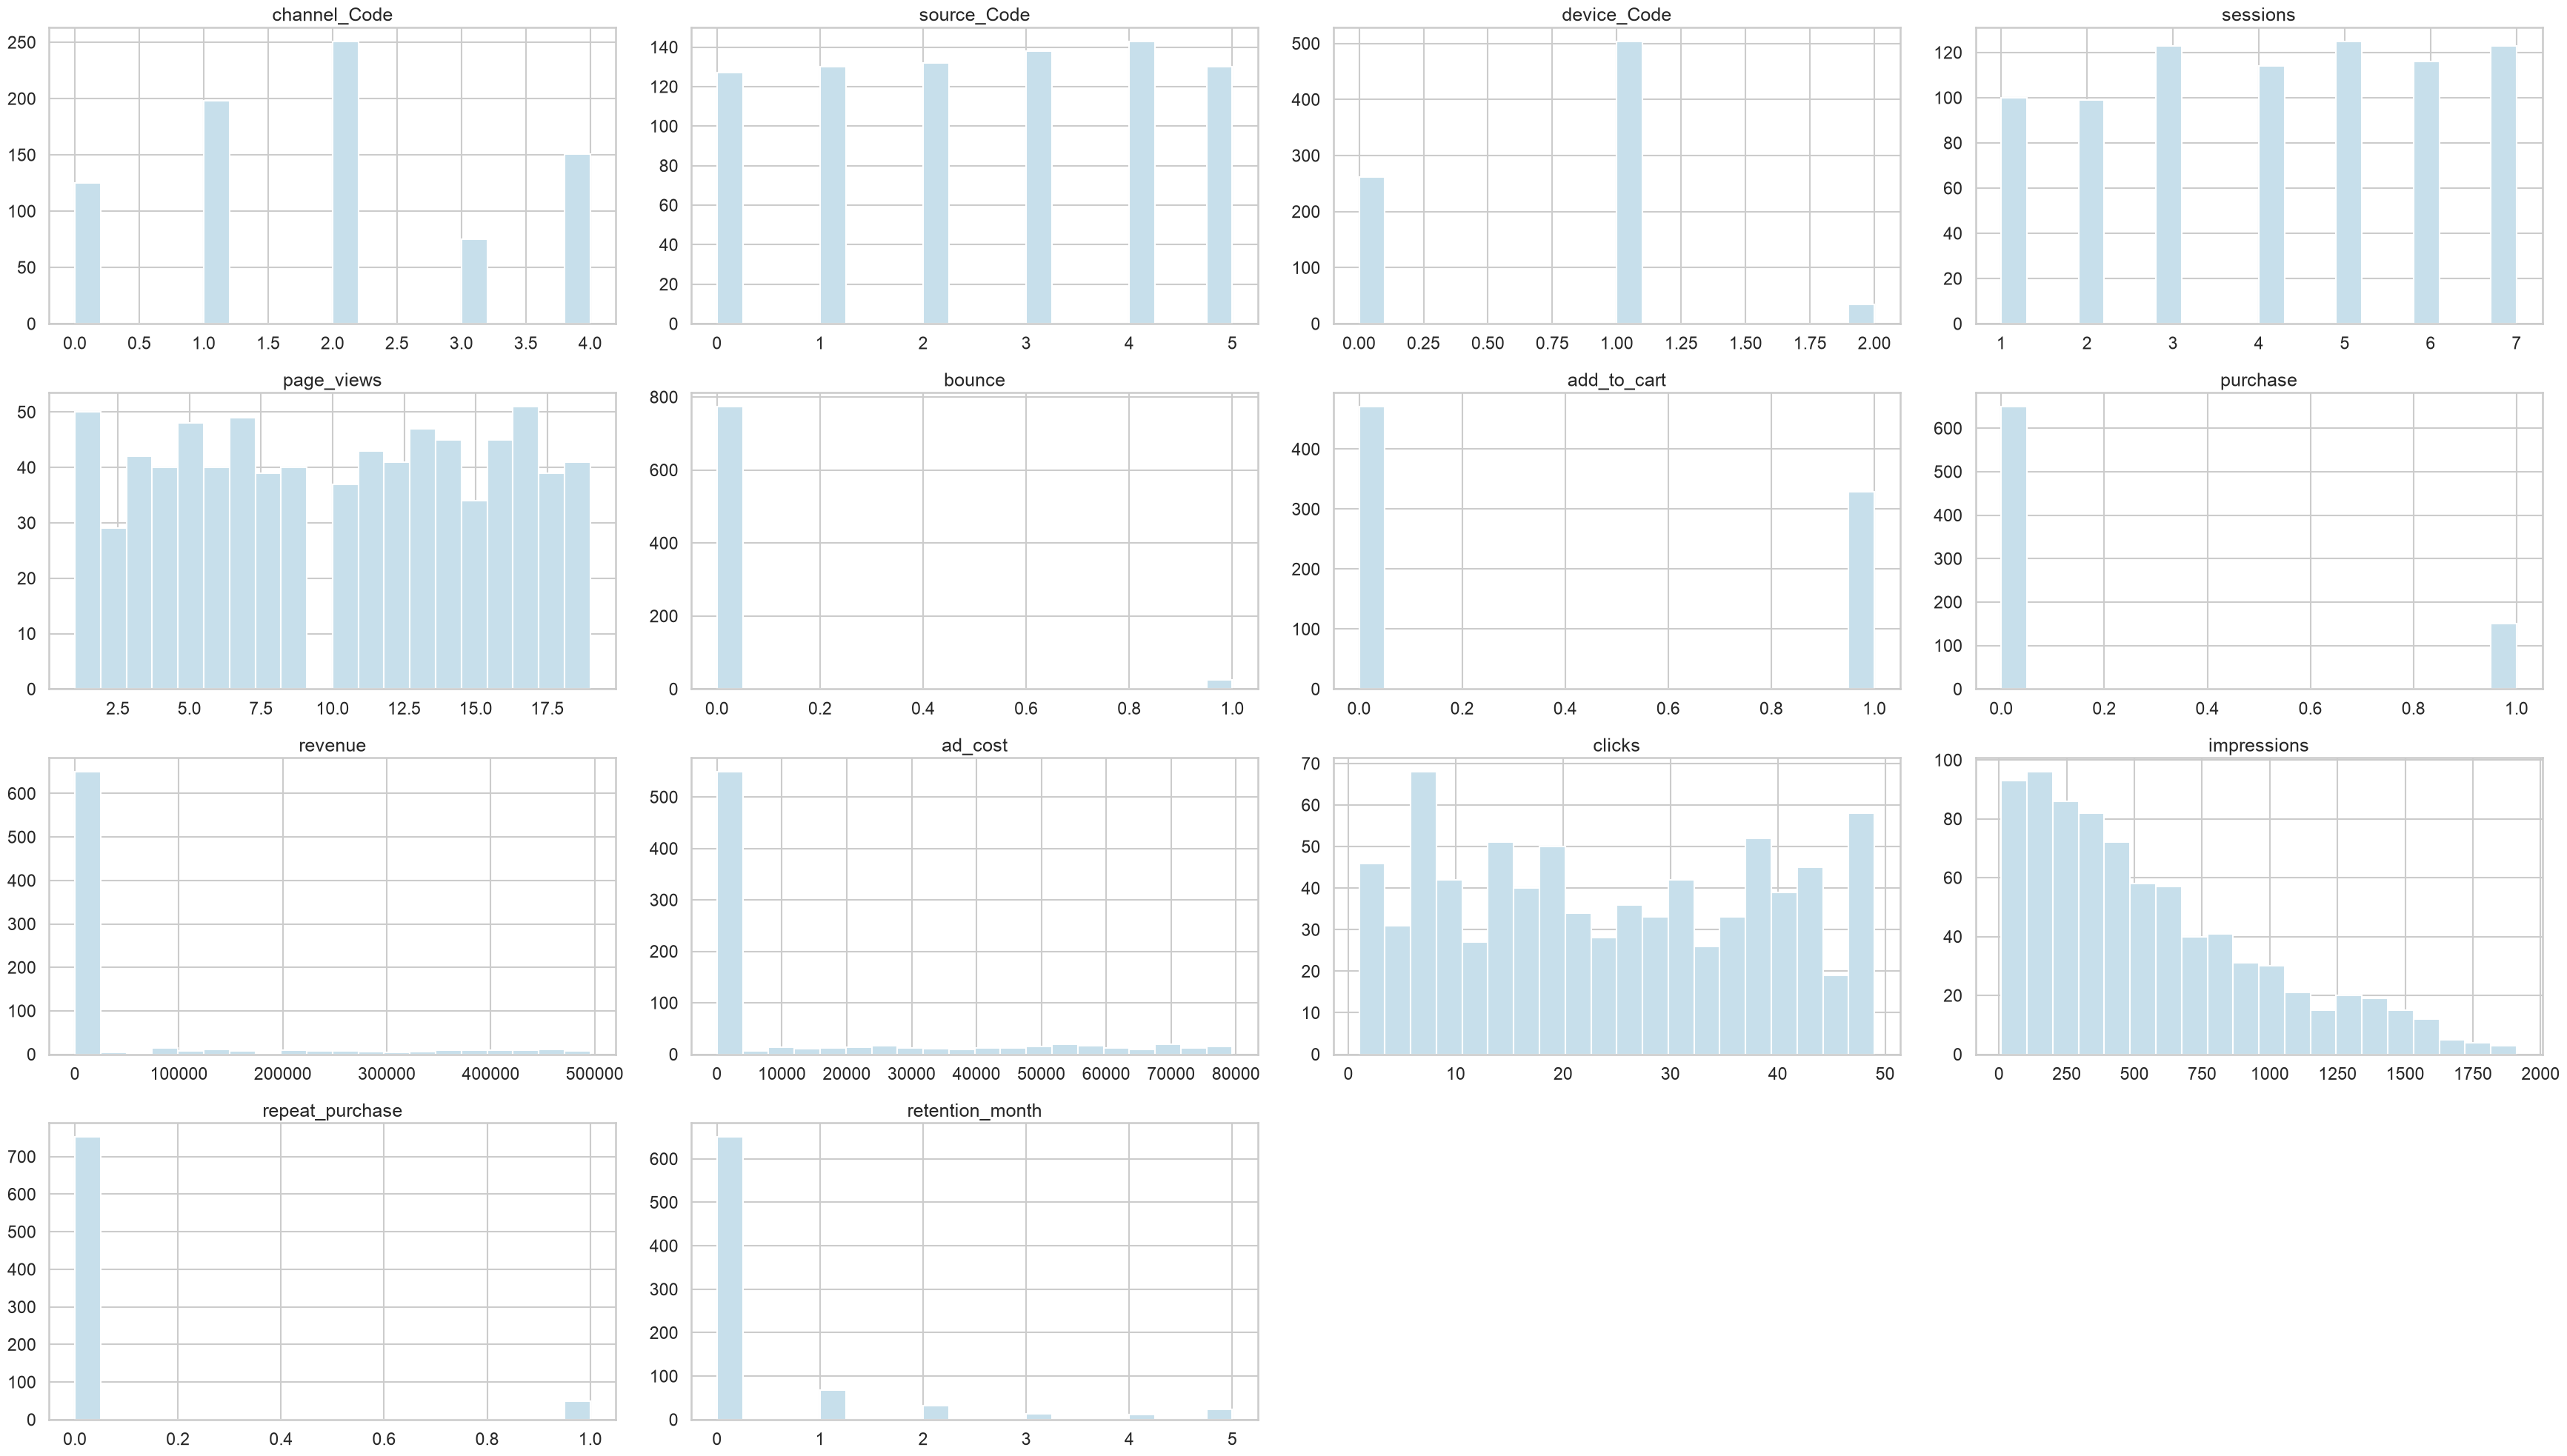

In [32]:
marketing_statistik.hist(
    bins=20,
    figsize=(35, 20)
)

plt.tight_layout()
plt.show()

# EDA

### Heatmap

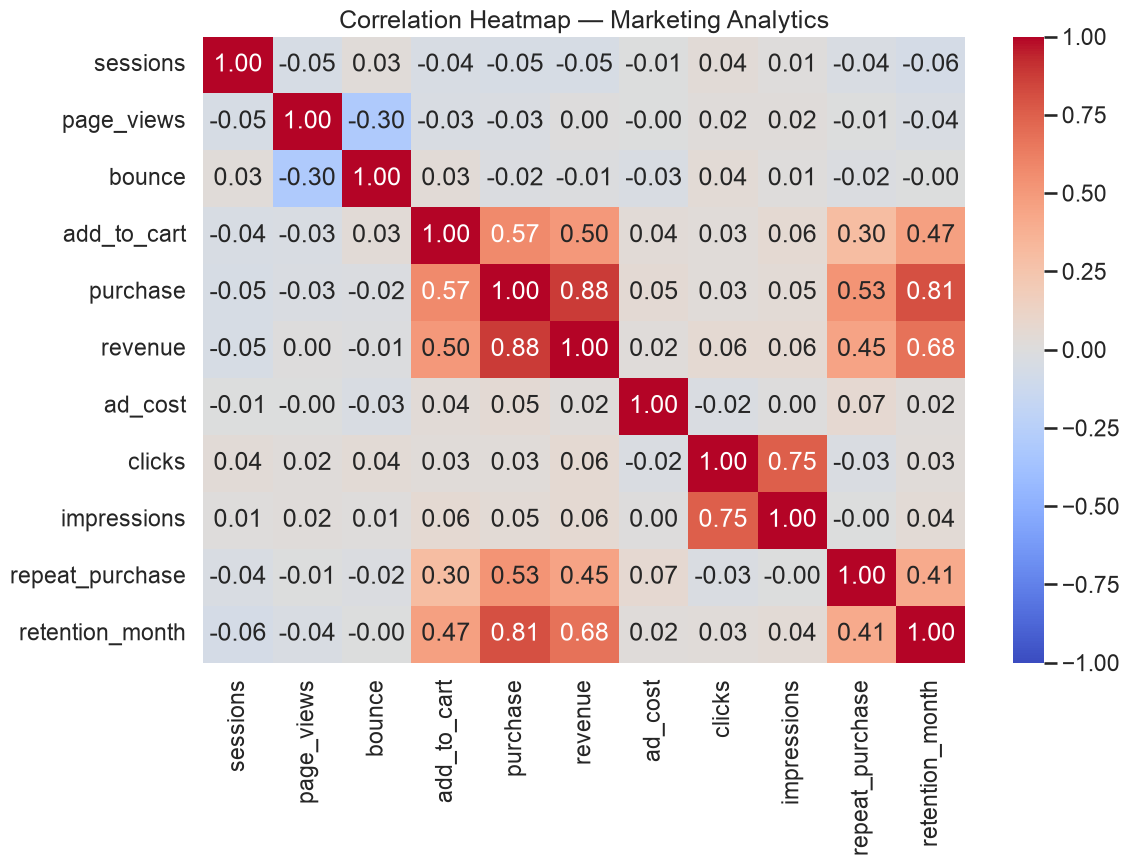

In [33]:
correlation_cols = [
    "sessions",
    "page_views",
    "bounce",
    "add_to_cart",
    "purchase",
    "revenue",
    "ad_cost",
    "clicks",
    "impressions",
    "repeat_purchase",
    "retention_month"
]

correlation_matrix = marketing[
    correlation_cols
].corr(method="pearson")

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap — Marketing Analytics")
plt.tight_layout()
plt.show()

### Univariat kategorikal


Distribusi channel


,channel,total_users,percentage
0,Paid Ads,251,31.37
1,Organic Search,198,24.75
2,Social Media,151,18.88
3,Email,125,15.62
4,Referral,75,9.38


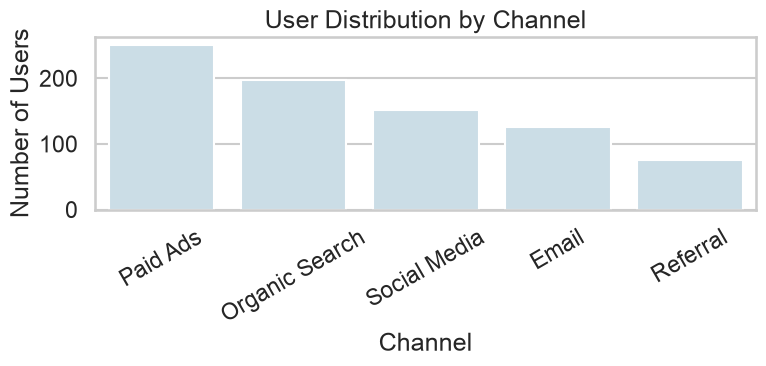


Distribusi source


,source,total_users,percentage
0,instagram,143,17.88
1,google,138,17.25
2,facebook,132,16.50
3,tiktok,130,16.25
4,email,130,16.25
5,direct,127,15.88


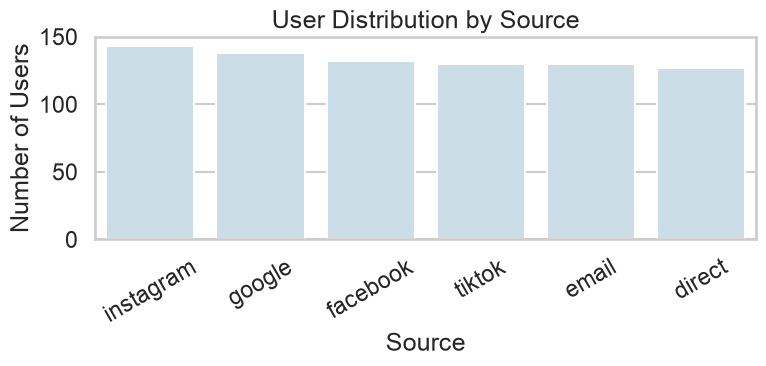


Distribusi device


,device,total_users,percentage
0,Mobile,504,63.00
1,Desktop,262,32.75
2,Tablet,34,4.25


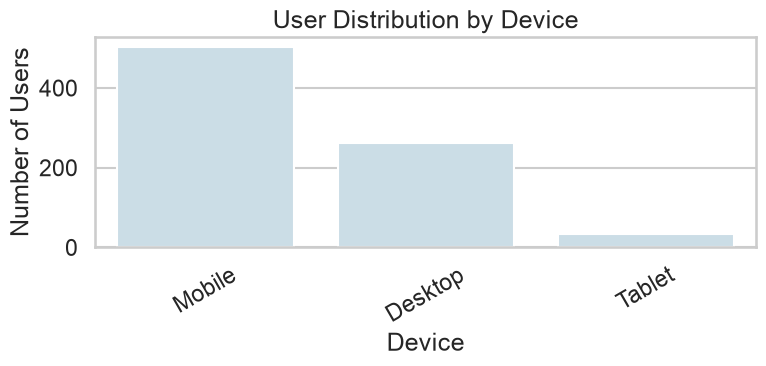

In [34]:
categorical_cols = ["channel", "source", "device"]

for col in categorical_cols:
    summary = (
        marketing[col]
        .value_counts()
        .reset_index()
    )

    summary.columns = [col, "total_users"]
    summary["percentage"] = (
        summary["total_users"] / len(marketing) * 100
    ).round(2)

    print(f"\nDistribusi {col}")
    display(summary)

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=marketing,
        x=col,
        order=marketing[col].value_counts().index
    )

    plt.title(f"User Distribution by {col.title()}")
    plt.xlabel(col.title())
    plt.ylabel("Number of Users")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

### Univariat Numerical

In [39]:
numeric_cols = [
    "sessions",
    "page_views",
    "revenue",
    "ad_cost",
    "clicks",
    "impressions",
    "retention_month"
]

display(
    marketing[numeric_cols].describe().round(2)
)

,sessions,page_views,revenue,ad_cost,clicks,impressions,retention_month
count,800.00,800.00,800.00,800.00,800.00,800.00,800.00
mean,4.13,10.05,51254.88,13686.13,24.37,553.38,0.43
std,1.97,5.48,121909.73,23499.47,14.37,427.27,1.10
min,1.00,1.00,0.00,0.00,1.00,8.00,0.00
25%,3.00,5.00,0.00,0.00,11.00,208.75,0.00
50%,4.00,10.00,0.00,0.00,23.00,442.00,0.00
75%,6.00,15.00,0.00,21996.75,37.00,812.00,0.00
max,7.00,19.00,495675.00,79437.00,49.00,1911.00,5.00


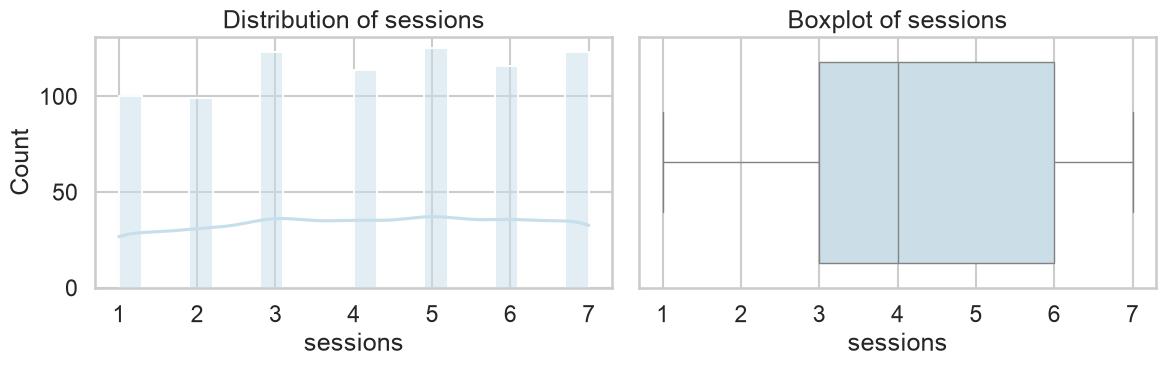

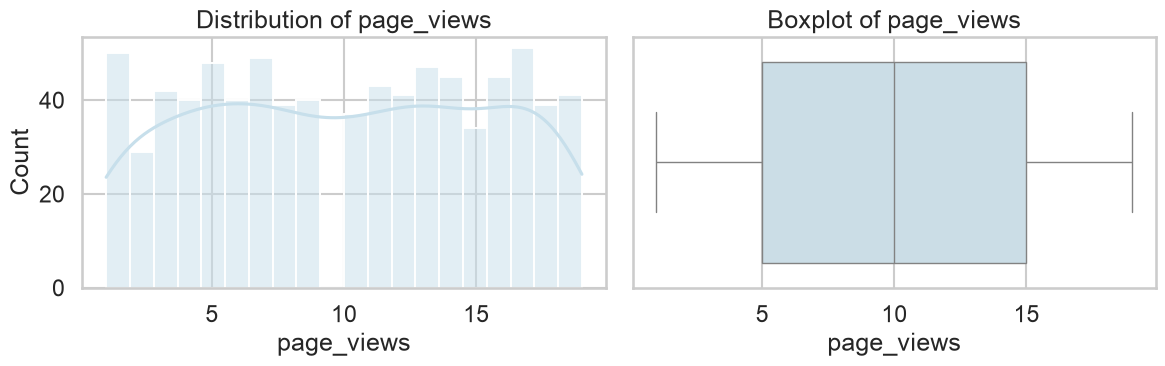

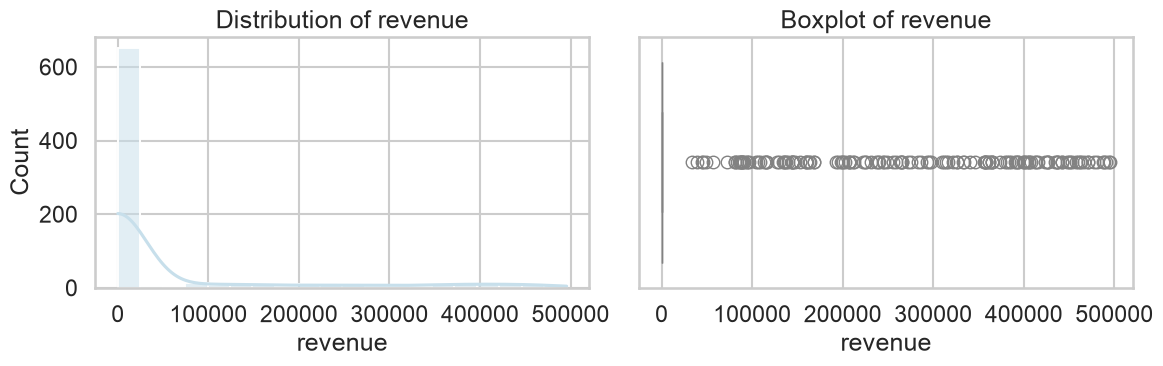

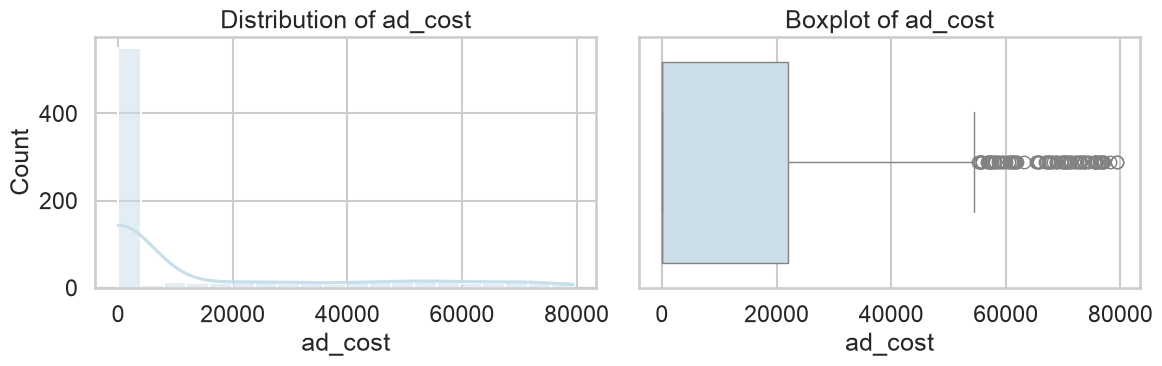

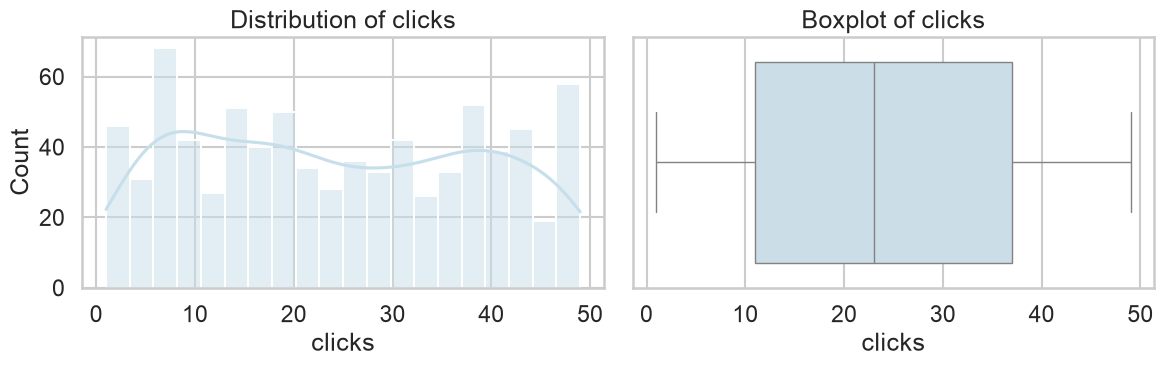

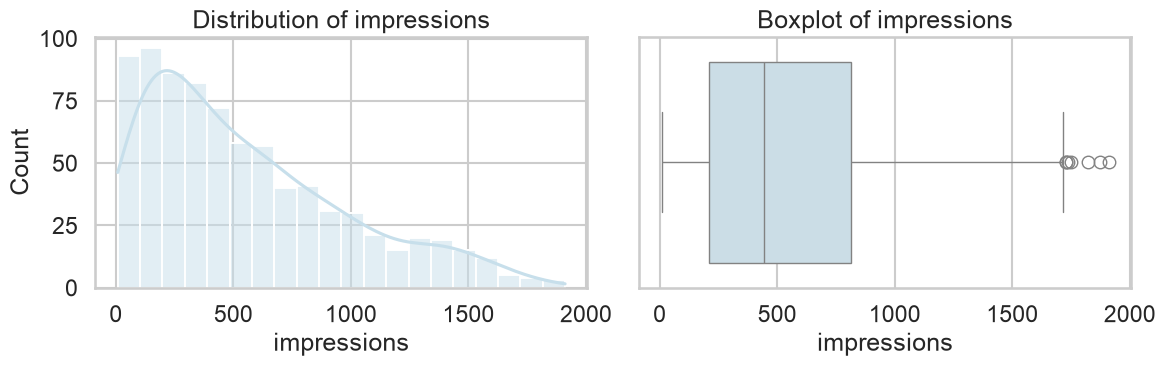

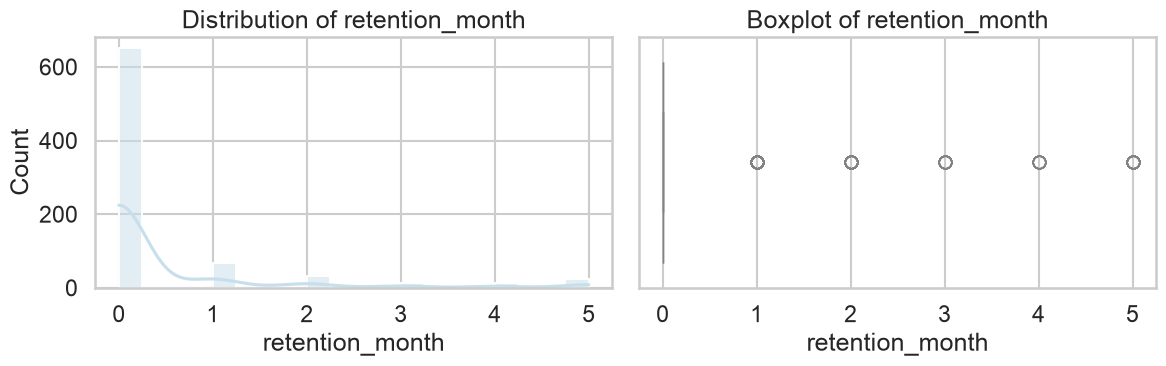

In [40]:
for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        data=marketing,
        x=col,
        bins=20,
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(f"Distribution of {col}")

    sns.boxplot(
        data=marketing,
        x=col,
        ax=axes[1]
    )

    axes[1].set_title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()

### Channel x Revenue

In [36]:
channel_revenue = (
    marketing.groupby("channel")
    .agg(
        total_users=("user_id", "nunique"),
        total_revenue=("revenue", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

display(channel_revenue)

,total_users,total_revenue
channel,,
Paid Ads,251,13177258
Social Media,151,10512961
Organic Search,198,7972474
Email,125,4894673
Referral,75,4446539


### Click x Impression

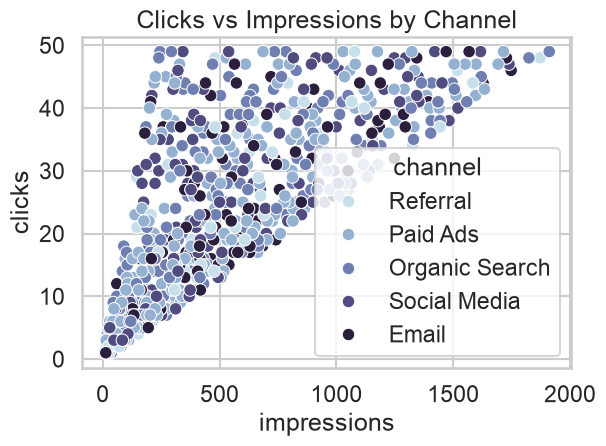

In [37]:
sns.scatterplot(
    data=marketing,
    x="impressions",
    y="clicks",
    hue="channel"
)

plt.title("Clicks vs Impressions by Channel")
plt.tight_layout()
plt.show()